In [1]:
import os
import time
import json
import random
import pickle
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from google.colab import drive

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Mount Google Drive
drive.mount("/content/drive")

# Project paths
PROJECT_DIR = "/content/drive/MyDrive/ICT4403_MT_Project"
DATA_DIR = os.path.join(PROJECT_DIR, "data2")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

# Hardware check
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU currently available. Setup can continue on CPU.")

Mounted at /content/drive
PyTorch version: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


In [2]:
# Verify the expected files
required_files = [
    "train.csv",
    "validation.csv",
    "test.csv",
    "metadata.json"
]

for filename in required_files:
    path = os.path.join(DATA_DIR, filename)
    print(
        f"{filename}:",
        "FOUND" if os.path.isfile(path) else "MISSING"
    )

# Stop if any required file is missing
missing = [
    f for f in required_files
    if not os.path.isfile(os.path.join(DATA_DIR, f))
]

if missing:
    raise FileNotFoundError(
        f"Missing files in {DATA_DIR}: {missing}"
    )

# Load the shared splits
train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(DATA_DIR, "validation.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

# Validate columns
for name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    assert list(df.columns) == ["en", "es"], (
        f"Unexpected columns in {name}: {df.columns.tolist()}"
    )
    assert not df[["en", "es"]].isna().any().any(), (
        f"Missing text found in {name}"
    )

print("\nDataset loaded successfully.")
print("Training pairs:", len(train_df))
print("Validation pairs:", len(val_df))
print("Test pairs:", len(test_df))

display(train_df.head(5))

train.csv: FOUND
validation.csv: FOUND
test.csv: FOUND
metadata.json: FOUND

Dataset loaded successfully.
Training pairs: 20000
Validation pairs: 1000
Test pairs: 1000


,en,es
0,Are you sure it's a kill chip and not a tracker?,¿Estás seguro que es un chip asesino y no un r...
1,The representative of Bolivia thanked the Secr...,El representante de Bolivia agradeció al Secre...
2,It is however acknowledged that it is appropri...,"No obstante, se ha admitido la conveniencia de..."
3,"I know, Brick.","Lo sé, Brick."
4,Don't fuck with the dosage. Wow.,No juegues con la medicación.


In [3]:
# Special tokens
PAD = "<pad>"
UNK = "<unk>"
BOS = "<bos>"
EOS = "<eos>"

PAD_ID = 0
UNK_ID = 1
BOS_ID = 2
EOS_ID = 3

MAX_VOCAB_SIZE = 16000
MIN_FREQUENCY = 2
MAX_LENGTH = 64

def tokenize(text):
    return str(text).strip().lower().split()

# Build vocabulary using TRAINING data only
counter = Counter()

for text in train_df["en"]:
    counter.update(tokenize(text))

for text in train_df["es"]:
    counter.update(tokenize(text))

special_tokens = [PAD, UNK, BOS, EOS]

vocab_words = [
    word
    for word, count in counter.most_common()
    if count >= MIN_FREQUENCY and word not in special_tokens
]

vocab_words = vocab_words[:MAX_VOCAB_SIZE - len(special_tokens)]

itos = special_tokens + vocab_words
stoi = {word: idx for idx, word in enumerate(itos)}

VOCAB_SIZE = len(itos)

print("Vocabulary size:", VOCAB_SIZE)
print("Special token IDs:")
print({"PAD": PAD_ID, "UNK": UNK_ID, "BOS": BOS_ID, "EOS": EOS_ID})

Vocabulary size: 16000
Special token IDs:
{'PAD': 0, 'UNK': 1, 'BOS': 2, 'EOS': 3}


In [4]:
def encode_source(text):
    ids = [stoi.get(token, UNK_ID) for token in tokenize(text)]
    return ids[:MAX_LENGTH - 1] + [EOS_ID]

def encode_target(text):
    ids = [stoi.get(token, UNK_ID) for token in tokenize(text)]
    return [BOS_ID] + ids[:MAX_LENGTH - 2] + [EOS_ID]

# Inspect an example
print("English:", train_df.iloc[0]["en"])
print("Source IDs:", encode_source(train_df.iloc[0]["en"]))

print("\nSpanish:", train_df.iloc[0]["es"])
print("Target IDs:", encode_target(train_df.iloc[0]["es"]))

English: Are you sure it's a kill chip and not a tracker?
Source IDs: [43, 18, 683, 71, 6, 708, 9569, 13, 46, 6, 1, 3]

Spanish: ¿Estás seguro que es un chip asesino y no un rastreador?
Target IDs: [2, 1011, 762, 9, 29, 23, 9569, 5611, 14, 19, 23, 1, 3]


In [5]:
class TranslationDataset(Dataset):
    def __init__(self, df):
        self.sources = [encode_source(x) for x in df["en"]]
        self.targets = [encode_target(x) for x in df["es"]]

    def __len__(self):
        return len(self.sources)

    def __getitem__(self, idx):
        return self.sources[idx], self.targets[idx]


def collate_batch(batch):
    sources, targets = zip(*batch)

    src = nn.utils.rnn.pad_sequence(
        [torch.tensor(x, dtype=torch.long) for x in sources],
        batch_first=True,
        padding_value=PAD_ID
    )

    tgt = nn.utils.rnn.pad_sequence(
        [torch.tensor(x, dtype=torch.long) for x in targets],
        batch_first=True,
        padding_value=PAD_ID
    )

    # Decoder input: BOS, token 1, token 2, ...
    # Expected output: token 1, token 2, ..., EOS
    return src, tgt[:, :-1], tgt[:, 1:]


BATCH_SIZE = 32

train_loader = DataLoader(
    TranslationDataset(train_df),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch
)

val_loader = DataLoader(
    TranslationDataset(val_df),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

# Check one batch
src, tgt_input, tgt_output = next(iter(train_loader))

print("Source shape:", src.shape)
print("Decoder input shape:", tgt_input.shape)
print("Expected output shape:", tgt_output.shape)

print("\nFirst target input:", tgt_input[0, :15].tolist())
print("First target output:", tgt_output[0, :15].tolist())

Source shape: torch.Size([32, 26])
Decoder input shape: torch.Size([32, 30])
Expected output shape: torch.Size([32, 30])

First target input: [2, 1, 66, 7, 1, 4, 1, 3, 0, 0, 0, 0, 0, 0, 0]
First target output: [1, 66, 7, 1, 4, 1, 3, 0, 0, 0, 0, 0, 0, 0, 0]


In [6]:
class BasicTransformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        d_model=128,
        nhead=4,
        num_layers=2,
        dim_feedforward=256,
        dropout=0.1,
        max_length=MAX_LENGTH
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, d_model, padding_idx=PAD_ID
        )
        self.position = nn.Embedding(max_length, d_model)

        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=num_layers,
            num_decoder_layers=num_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )

        self.output = nn.Linear(d_model, vocab_size)
        self.d_model = d_model

    def forward(self, src, tgt_input):
        src_positions = torch.arange(src.size(1), device=src.device)
        tgt_positions = torch.arange(tgt_input.size(1), device=tgt_input.device)

        # Token + positional embeddings
        src_emb = (
            self.embedding(src) * (self.d_model ** 0.5)
            + self.position(src_positions)[None, :, :]
        )

        tgt_emb = (
            self.embedding(tgt_input) * (self.d_model ** 0.5)
            + self.position(tgt_positions)[None, :, :]
        )

        # Prevent decoder positions from seeing future tokens
        tgt_len = tgt_input.size(1)
        causal_mask = torch.triu(
            torch.ones(
                tgt_len, tgt_len,
                dtype=torch.bool,
                device=tgt_input.device
            ),
            diagonal=1
        )

        src_padding_mask = src.eq(PAD_ID)
        tgt_padding_mask = tgt_input.eq(PAD_ID)

        output = self.transformer(
            src_emb,
            tgt_emb,
            tgt_mask=causal_mask,
            src_key_padding_mask=src_padding_mask,
            tgt_key_padding_mask=tgt_padding_mask,
            memory_key_padding_mask=src_padding_mask
        )

        return self.output(output)


model = BasicTransformer(VOCAB_SIZE).to(DEVICE)

parameter_count = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Device:", DEVICE)
print(f"Trainable parameters: {parameter_count:,}")

Device: cuda
Trainable parameters: 4,783,232


In [7]:
model.eval()

src, tgt_input, tgt_output = next(iter(train_loader))

src = src.to(DEVICE)
tgt_input = tgt_input.to(DEVICE)
tgt_output = tgt_output.to(DEVICE)

with torch.no_grad():
    logits = model(src, tgt_input)

print("Logits shape:", logits.shape)
print("Expected target shape:", tgt_output.shape)

assert logits.shape[:2] == tgt_output.shape
assert logits.shape[-1] == VOCAB_SIZE

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

loss = criterion(
    logits.reshape(-1, VOCAB_SIZE),
    tgt_output.reshape(-1)
)

print("Initial batch loss:", round(loss.item(), 4))
print("Forward pass successful.")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Logits shape: torch.Size([32, 63, 16000])
Expected target shape: torch.Size([32, 63])
Initial batch loss: 9.7562
Forward pass successful.


In [8]:
import pickle
import json
import os

config = {
    "model": "Basic Transformer",
    "architecture": "Encoder-decoder",
    "source_language": "English",
    "target_language": "Spanish",
    "dataset": "OPUS-100",
    "seed": SEED,
    "vocab_size": VOCAB_SIZE,
    "max_length": MAX_LENGTH,
    "d_model": 128,
    "nhead": 4,
    "num_layers": 2,
    "dim_feedforward": 256,
    "batch_size": BATCH_SIZE,
    "parameter_count": parameter_count
}

with open(os.path.join(MODEL_DIR, "basic_transformer_vocab.pkl"), "wb") as f:
    pickle.dump({"itos": itos, "stoi": stoi}, f)

with open(os.path.join(MODEL_DIR, "basic_transformer_config.json"), "w") as f:
    json.dump(config, f, indent=2)

print("Vocabulary and configuration saved.")
print("Model parameters:", f"{parameter_count:,}")

Vocabulary and configuration saved.
Model parameters: 4,783,232


In [9]:
INITIAL_MODEL_PATH = os.path.join(
    MODEL_DIR, "basic_transformer_initial.pt"
)

torch.save(model.state_dict(), INITIAL_MODEL_PATH)

print("Initial model weights saved to:")
print(INITIAL_MODEL_PATH)

print("File size (MB):", round(
    os.path.getsize(INITIAL_MODEL_PATH) / (1024 ** 2), 2
))

Initial model weights saved to:
/content/drive/MyDrive/ICT4403_MT_Project/models/basic_transformer_initial.pt
File size (MB): 18.27


In [10]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. Do not start full training on CPU yet.")

CUDA available: True
GPU: Tesla T4


In [11]:
# Training configuration — does not start training

EPOCHS = 10
LEARNING_RATE = 3e-4
PATIENCE = 3
GRAD_CLIP = 1.0

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.98),
    eps=1e-9
)

print("Training configuration prepared.")
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Early-stopping patience:", PATIENCE)
print("Current device:", DEVICE)

Training configuration prepared.
Epochs: 10
Learning rate: 0.0003
Early-stopping patience: 3
Current device: cuda


In [12]:
# Training configuration — preparation only
EPOCHS = 10
LEARNING_RATE = 3e-4
PATIENCE = 3
GRAD_CLIP = 1.0

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.98),
    eps=1e-9
)

training_config = {
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "patience": PATIENCE,
    "gradient_clipping": GRAD_CLIP,
    "batch_size": BATCH_SIZE,
    "device_used_for_preparation": str(DEVICE)
}

with open(os.path.join(MODEL_DIR, "basic_transformer_training_config.json"), "w") as f:
    json.dump(training_config, f, indent=4)

print("Training configuration saved.")
print(training_config)

Training configuration saved.
{'epochs': 10, 'learning_rate': 0.0003, 'patience': 3, 'gradient_clipping': 1.0, 'batch_size': 32, 'device_used_for_preparation': 'cuda'}


In [13]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_tokens = 0

    for src, tgt_input, tgt_output in loader:
        src = src.to(DEVICE)
        tgt_input = tgt_input.to(DEVICE)
        tgt_output = tgt_output.to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(src, tgt_input)

            loss = criterion(
                logits.reshape(-1, logits.size(-1)),
                tgt_output.reshape(-1)
            )

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), GRAD_CLIP
                )
                optimizer.step()

        valid_tokens = tgt_output.ne(PAD_ID).sum().item()
        total_loss += loss.item() * valid_tokens
        total_tokens += valid_tokens

    return total_loss / max(total_tokens, 1)


print("Training and validation function defined.")

Training and validation function defined.


In [14]:
BEST_MODEL_PATH = os.path.join(
    MODEL_DIR, "basic_transformer_best.pt"
)

CHECKPOINT_PATH = os.path.join(
    MODEL_DIR, "basic_transformer_checkpoint.pt"
)

def save_checkpoint(epoch, best_val_loss, patience_count):
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_loss": best_val_loss,
        "patience_count": patience_count
    }, CHECKPOINT_PATH)

def load_checkpoint():
    if not os.path.exists(CHECKPOINT_PATH):
        print("No training checkpoint exists yet.")
        return None

    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    print("Checkpoint loaded from epoch", checkpoint["epoch"] + 1)
    return checkpoint

print("Checkpoint functions ready.")

Checkpoint functions ready.


In [15]:
print("Device:", DEVICE)
print("Training examples:", len(train_df))
print("Validation examples:", len(val_df))
print("Test examples:", len(test_df))
print("Vocabulary size:", VOCAB_SIZE)
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Training function:", callable(run_epoch))
print("Checkpoint function:", callable(save_checkpoint))
print("Saved configuration:", os.path.exists(
    os.path.join(MODEL_DIR, "basic_transformer_training_config.json")
))

Device: cuda
Training examples: 20000
Validation examples: 1000
Test examples: 1000
Vocabulary size: 16000
Model parameters: 4783232
Training function: True
Checkpoint function: True
Saved configuration: True


In [16]:
import torch
import os

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    print("No GPU detected. Do not start training yet.")

print("Train examples:", len(train_df))
print("Validation examples:", len(val_df))
print("Test examples:", len(test_df))
print("Vocabulary size:", VOCAB_SIZE)
print("Model parameters:", sum(p.numel() for p in model.parameters()))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 15.64
Train examples: 20000
Validation examples: 1000
Test examples: 1000
Vocabulary size: 16000
Model parameters: 4783232


In [17]:
import torch.nn as nn
import time
import json
import os

EPOCHS = 10
LEARNING_RATE = 3e-4
PATIENCE = 3
GRAD_CLIP = 1.0

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.98),
    eps=1e-9
)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR, "basic_transformer_best.pt"
)
CHECKPOINT_PATH = os.path.join(
    MODEL_DIR, "basic_transformer_checkpoint.pt"
)

print("Training setup ready.")

Training setup ready.


In [19]:
best_val_loss = float("inf")
patience_count = 0
training_history = []
start_time = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()

    train_loss = run_epoch(
        model, train_loader, optimizer=optimizer
    )
    val_loss = run_epoch(
        model, val_loader, optimizer=None
    )

    epoch_seconds = time.time() - epoch_start

    record = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "epoch_seconds": epoch_seconds
    }
    training_history.append(record)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Time: {epoch_seconds / 60:.2f} min"
    )

    # Save the best model whenever validation loss improves
    if val_loss < best_val_loss:
      best_val_loss = val_loss
      patience_count = 0

      torch.save({
          "model_state_dict": model.state_dict(),
          "epoch": epoch + 1,
          "best_val_loss": best_val_loss,
          "config": config
      }, BEST_MODEL_PATH)

      print("Best model saved.")
    else:
      patience_count += 1

# Save a resumable checkpoint after every epoch
    torch.save({
      "epoch": epoch + 1,
      "model_state_dict": model.state_dict(),
      "optimizer_state_dict": optimizer.state_dict(),
      "best_val_loss": best_val_loss,
      "patience_count": patience_count,
      "training_history": training_history
    }, CHECKPOINT_PATH)

    if patience_count >= PATIENCE:
        print("Early stopping.")
        break

training_minutes = (time.time() - start_time) / 60

with open(
    os.path.join(RESULTS_DIR, "basic_transformer_training_history.json"),
    "w"
) as f:
    json.dump(training_history, f, indent=2)

print(f"\nTraining finished in {training_minutes:.2f} minutes.")
print("Best validation loss:", best_val_loss)
print("Best model:", BEST_MODEL_PATH)

Epoch 1/10 | Train loss: 5.7648 | Val loss: 4.9945 | Time: 0.24 min
Best model saved.
Epoch 2/10 | Train loss: 5.0991 | Val loss: 4.7660 | Time: 0.24 min
Best model saved.
Epoch 3/10 | Train loss: 4.8780 | Val loss: 4.6454 | Time: 0.26 min
Best model saved.
Epoch 4/10 | Train loss: 4.7283 | Val loss: 4.5517 | Time: 0.25 min
Best model saved.
Epoch 5/10 | Train loss: 4.6146 | Val loss: 4.4819 | Time: 0.26 min
Best model saved.
Epoch 6/10 | Train loss: 4.5139 | Val loss: 4.4299 | Time: 0.24 min
Best model saved.
Epoch 7/10 | Train loss: 4.4234 | Val loss: 4.3822 | Time: 0.24 min
Best model saved.
Epoch 8/10 | Train loss: 4.3431 | Val loss: 4.3435 | Time: 0.24 min
Best model saved.
Epoch 9/10 | Train loss: 4.2656 | Val loss: 4.3129 | Time: 0.25 min
Best model saved.
Epoch 10/10 | Train loss: 4.1941 | Val loss: 4.2787 | Time: 0.26 min
Best model saved.

Training finished in 2.54 minutes.
Best validation loss: 4.278661161674156
Best model: /content/drive/MyDrive/ICT4403_MT_Project/models/ba

In [22]:
import os
import json
import time

final_training_summary = {
    "model": "Basic Transformer",
    "architecture": "Encoder-decoder",
    "epochs_completed": len(training_history),
    "training_minutes": training_minutes,
    "best_validation_loss": best_val_loss,
    "parameter_count": sum(p.numel() for p in model.parameters()),
    "best_model_path": BEST_MODEL_PATH,
    "checkpoint_path": CHECKPOINT_PATH
}

summary_path = os.path.join(
    RESULTS_DIR, "basic_transformer_training_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(final_training_summary, f, indent=2)

print(json.dumps(final_training_summary, indent=2))
print("Training summary saved:", summary_path)

{
  "model": "Basic Transformer",
  "architecture": "Encoder-decoder",
  "epochs_completed": 10,
  "training_minutes": 2.5400609890619914,
  "best_validation_loss": 4.278661161674156,
  "parameter_count": 4783232,
  "best_model_path": "/content/drive/MyDrive/ICT4403_MT_Project/models/basic_transformer_best.pt",
  "checkpoint_path": "/content/drive/MyDrive/ICT4403_MT_Project/models/basic_transformer_checkpoint.pt"
}
Training summary saved: /content/drive/MyDrive/ICT4403_MT_Project/results/basic_transformer_training_summary.json


In [23]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print("Best model loaded successfully.")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])
print("Device:", DEVICE)

Best model loaded successfully.
Best epoch: 10
Best validation loss: 4.278661161674156
Device: cuda


In [24]:
def translate_basic_transformer(text, max_length=MAX_LENGTH):
    model.eval()

    source_ids = encode_source(text)

    src = torch.tensor(
        source_ids,
        dtype=torch.long
    ).unsqueeze(0).to(DEVICE)

    generated = [BOS_ID]

    for _ in range(max_length - 1):
        tgt = torch.tensor(
            generated,
            dtype=torch.long
        ).unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            logits = model(src, tgt)

        next_id = logits[0, -1].argmax(dim=-1).item()

        if next_id == EOS_ID:
            break

        generated.append(next_id)

    tokens = [
        itos[token_id]
        for token_id in generated[1:]
        if token_id not in (PAD_ID, BOS_ID, EOS_ID)
    ]

    return " ".join(tokens)


print("Translation function defined.")

Translation function defined.


In [25]:
sample = test_df.iloc[0]

print("English input:", sample["en"])
print("Reference Spanish:", sample["es"])
print("Model prediction:", translate_basic_transformer(sample["en"]))

English input: We humans will inevitably end up controlling our own evolution, and, because our power is emergent from nature we will make use of this acquired capacity sooner or later, for better or worse.
Reference Spanish: Nosotros humanos terminaremos inevitablemente controlando nuestra propia evolución y, puesto que nuestro poder emerge de la naturaleza, tarde o temprano utilizaremos esa capacidad adquirida, para bien o para mal.
Model prediction: tenemos que <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> o <unk> <unk> <unk> <unk> <unk> <unk> o <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> o <unk> <unk>


In [26]:
predictions = []
inference_start = time.time()

for i, text in enumerate(test_df["en"].astype(str)):
    prediction = translate_basic_transformer(text)
    predictions.append(prediction)

    if (i + 1) % 100 == 0:
        print(f"Translated {i + 1}/{len(test_df)}")

inference_seconds = time.time() - inference_start

prediction_path = os.path.join(
    RESULTS_DIR, "basic_transformer_predictions.csv"
)

pd.DataFrame({
    "en": test_df["en"].astype(str),
    "reference": test_df["es"].astype(str),
    "prediction": predictions
}).to_csv(prediction_path, index=False)

print(f"\nInference time: {inference_seconds:.2f} seconds")
print(f"Average per sentence: {inference_seconds / len(predictions):.3f} seconds")
print("Predictions saved:", prediction_path)

Translated 100/1000
Translated 200/1000
Translated 300/1000
Translated 400/1000
Translated 500/1000
Translated 600/1000
Translated 700/1000
Translated 800/1000
Translated 900/1000
Translated 1000/1000

Inference time: 73.14 seconds
Average per sentence: 0.073 seconds
Predictions saved: /content/drive/MyDrive/ICT4403_MT_Project/results/basic_transformer_predictions.csv


In [27]:
%pip install -q sacrebleu
import sacrebleu

references = test_df["es"].astype(str).tolist()

bleu = sacrebleu.corpus_bleu(
    predictions,
    [references]
).score

chrf = sacrebleu.corpus_chrf(
    predictions,
    [references]
).score

basic_results = {
    "model": "Basic Transformer",
    "architecture": "Encoder-decoder",
    "parameters": sum(p.numel() for p in model.parameters()),
    "epochs_completed": len(training_history),
    "training_minutes": training_minutes,
    "inference_seconds_for_1000": inference_seconds,
    "BLEU": bleu,
    "chrF": chrf
}

metrics_path = os.path.join(
    RESULTS_DIR, "basic_transformer_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(basic_results, f, indent=2)

print(json.dumps(basic_results, indent=2))
print("Metrics saved:", metrics_path)

{
  "model": "Basic Transformer",
  "architecture": "Encoder-decoder",
  "parameters": 4783232,
  "epochs_completed": 10,
  "training_minutes": 2.5400609890619914,
  "inference_seconds_for_1000": 73.14120030403137,
  "BLEU": 0.1301482269605072,
  "chrF": 6.109794803659405
}
Metrics saved: /content/drive/MyDrive/ICT4403_MT_Project/results/basic_transformer_metrics.json


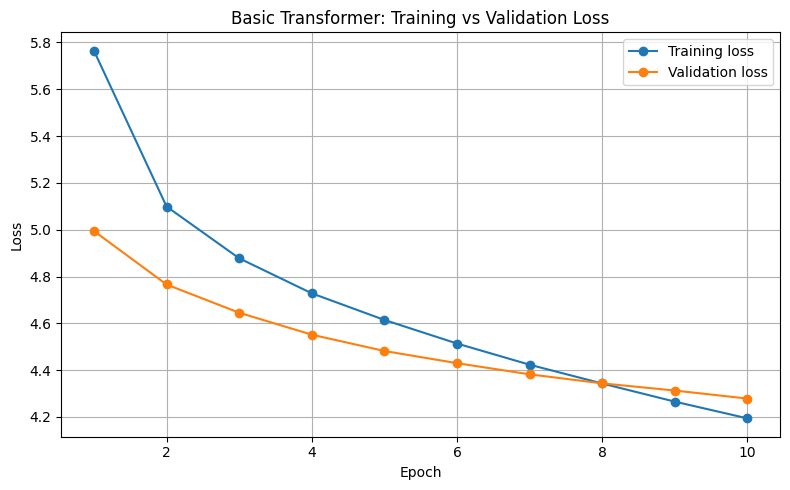

Loss curve saved: /content/drive/MyDrive/ICT4403_MT_Project/results/basic_transformer_loss_curve.png


In [28]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(training_history)

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training loss")
plt.plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Basic Transformer: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plot_path = os.path.join(
    RESULTS_DIR, "basic_transformer_loss_curve.png"
)

plt.savefig(plot_path, dpi=150)
plt.show()

print("Loss curve saved:", plot_path)

In [29]:
expected_files = [
    BEST_MODEL_PATH,
    CHECKPOINT_PATH,
    os.path.join(RESULTS_DIR, "basic_transformer_training_history.json"),
    summary_path,
    prediction_path,
    metrics_path,
    plot_path
]

for path in expected_files:
    print(
        "OK" if os.path.exists(path) else "MISSING",
        path
    )

OK /content/drive/MyDrive/ICT4403_MT_Project/models/basic_transformer_best.pt
OK /content/drive/MyDrive/ICT4403_MT_Project/models/basic_transformer_checkpoint.pt
OK /content/drive/MyDrive/ICT4403_MT_Project/results/basic_transformer_training_history.json
OK /content/drive/MyDrive/ICT4403_MT_Project/results/basic_transformer_training_summary.json
OK /content/drive/MyDrive/ICT4403_MT_Project/results/basic_transformer_predictions.csv
OK /content/drive/MyDrive/ICT4403_MT_Project/results/basic_transformer_metrics.json
OK /content/drive/MyDrive/ICT4403_MT_Project/results/basic_transformer_loss_curve.png


In [30]:
# Inspect 10 translations from the saved predictions

pred_path = os.path.join(
    RESULTS_DIR, "basic_transformer_predictions.csv"
)

pred_df = pd.read_csv(pred_path)

for i in range(10):
    print(f"\nExample {i + 1}")
    print("English:   ", pred_df.loc[i, "en"])
    print("Reference: ", pred_df.loc[i, "reference"])
    print("Prediction:", pred_df.loc[i, "prediction"])


Example 1
English:    We humans will inevitably end up controlling our own evolution, and, because our power is emergent from nature we will make use of this acquired capacity sooner or later, for better or worse.
Reference:  Nosotros humanos terminaremos inevitablemente controlando nuestra propia evolución y, puesto que nuestro poder emerge de la naturaleza, tarde o temprano utilizaremos esa capacidad adquirida, para bien o para mal.
Prediction: tenemos que <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> o <unk> <unk> <unk> <unk> <unk> <unk> o <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> o <unk> <unk>

Example 2
English:    If she had not rented quarter in this building our lives would have be very different.
Reference:  Si no hubiera rentado un cuarto en este edificio nuestras vidas habrían sido muy diferentes.
Prediction: si no se <unk> en este <unk> no se <unk